<a href="https://colab.research.google.com/github/fischdakid/is-4487-labs/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [18]:
# Add code here 🔧
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [19]:
df = pd.read_csv('/content/cleaned_airbnb_data_6.csv')

print(df.shape)
df.head()

(6930, 80)


,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,price_was_missing,has_reviews,rating_label,days_since_last_review
0,157612,https://www.airbnb.com/rooms/157612,20260628205933,2026-06-29,city scrape,New attic space/single & Dble room,"The loft space is a small but cosy, private an...",https://a0.muscache.com/pictures/18150718/745a...,757016,https://www.airbnb.com/users/show/757016,...,4.88,1,1,0,0,1.05,False,True,4.92,21.0
1,360142,https://www.airbnb.com/rooms/360142,20260628205933,2026-06-28,city scrape,Light double room next to bathroom,Lovely bright room at rear of house. Double be...,https://a0.muscache.com/pictures/13631809/c147...,1821587,https://www.airbnb.com/users/show/1821587,...,4.75,2,0,2,0,0.33,False,True,4.81,118.0
2,388138,https://www.airbnb.com/rooms/388138,20260628205933,2026-06-29,city scrape,Boutique Cottage with exclusive use indoor pool.,A beautifully converted historic coach house w...,https://a0.muscache.com/pictures/hosting/Hosti...,1942000,https://www.airbnb.com/users/show/1942000,...,4.86,1,1,0,0,0.18,False,True,4.9,11.0
3,391704,https://www.airbnb.com/rooms/391704,20260628205933,2026-06-29,city scrape,bright dble room,NaN,https://a0.muscache.com/pictures/4394101/f8878...,1958935,https://www.airbnb.com/users/show/1958935,...,5.00,1,0,1,0,0.01,False,True,5.0,2774.0
4,412687,https://www.airbnb.com/rooms/412687,20260628205933,2026-06-29,city scrape,Ivy Bank.Altrincham's original & cosy Airbnb flat,A cosy well equipped one bedroom basement flat...,https://a0.muscache.com/pictures/8818620/0e8d4...,2053716,https://www.airbnb.com/users/show/2053716,...,4.95,1,1,0,0,2.80,False,True,4.98,0.0


## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

Skewness (original): 8.0


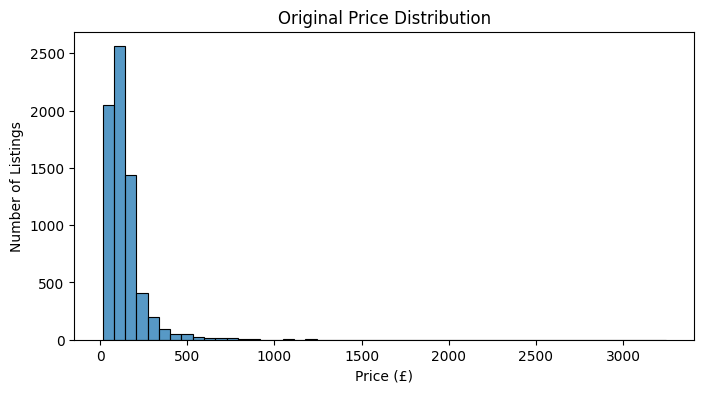

Skewness (log): 0.19


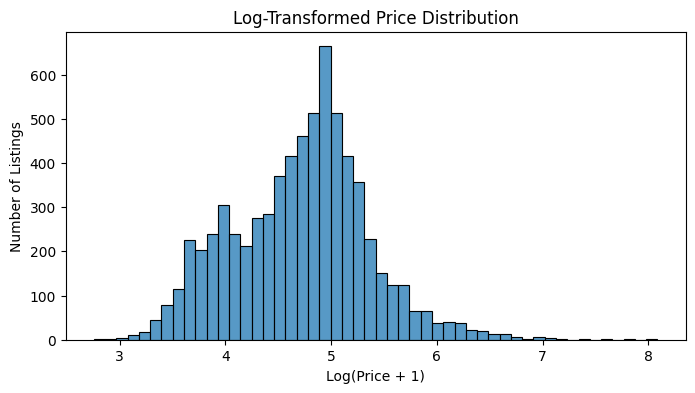

In [20]:
# Add code here 🔧
df['price'] = df['price'].replace(r'[\$,]', '', regex=True).astype(float)

price_data = df['price'].dropna()

print("Skewness (original):", round(price_data.skew(), 2))

plt.figure(figsize=(8, 4))
sns.histplot(price_data, bins=50)
plt.title('Original Price Distribution')
plt.xlabel('Price (£)')
plt.ylabel('Number of Listings')
plt.show()

df['log_price'] = np.log1p(df['price'])

print("Skewness (log):", round(df['log_price'].skew(), 2))

plt.figure(figsize=(8, 4))
sns.histplot(df['log_price'].dropna(), bins=50)
plt.title('Log-Transformed Price Distribution')
plt.xlabel('Log(Price + 1)')
plt.ylabel('Number of Listings')
plt.show()


### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. I looked into the price column which showsme the nightly rate for each listing.

2. I tried out the log transformation. The price is very skewed to the right with most listing having moderate prices and a few listing on the high priced side which stretch the tail. The log transformation helps me compress the extremes in the data set.

3. The transformation gave me a much more balanced view into the dataset and specifically the prices. It makes it easier for me to see patterns and makes sure models aren't dominated by outliers. It makes it easy for workers or analysts to understand the data.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [21]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

print(df[['price', 'minimum_nights']].describe())

# Min-Max
minmax = MinMaxScaler()
df['minimum_nights_minmax'] = minmax.fit_transform(df[['minimum_nights']])

# Z-score
standard = StandardScaler()
df['price_zscore'] = standard.fit_transform(df[['price']])

print(df[['minimum_nights_minmax', 'price_zscore']].describe())
df[['minimum_nights', 'minimum_nights_minmax', 'price', 'price_zscore']].head()

             price  minimum_nights
count  6930.000000     6929.000000
mean    137.761642        2.747150
std     126.656500        4.567479
min      14.730000        1.000000
25%      69.802500        1.000000
50%     117.415000        1.000000
75%     163.187500        2.000000
max    3248.000000       31.000000
       minimum_nights_minmax  price_zscore
count            6929.000000  6.930000e+03
mean                0.058238  1.297022e-16
std                 0.152249  1.000072e+00
min                 0.000000 -9.714505e-01
25%                 0.000000 -5.366013e-01
50%                 0.000000 -1.606559e-01
75%                 0.033333  2.007611e-01
max                 1.000000  2.455826e+01


,minimum_nights,minimum_nights_minmax,price,price_zscore
0,2.0,0.033333,76.0,-0.487666
1,3.0,0.066667,67.0,-0.558730
2,1.0,0.000000,190.0,0.412471
3,1.0,0.000000,30.0,-0.850879
4,2.0,0.033333,101.0,-0.290268



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. I scaled the minimum nights using min-max scaling making it run from 0 to 1. Along with that I scaled price with the Z score making it possible to see how each value sits in comparision to the standaard deviation.

2. These scaled values are more useful than the originals because they help with comparing/combining variables with different ranges. It standardizes the data so we can see variables compared without too much dominating from a single variable like price.

3. The people that are working on building pricing or recommendation models would benefit because scaled inputs keep variables from outweighing one another. Along with that the revenue managers could benefit from the z scores so they can flag unusually high or low listings.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

count    6930.000000
mean       38.649062
std        93.126274
min         0.000000
25%         1.000000
50%         9.000000
75%        40.000000
max      4100.000000
Name: number_of_reviews, dtype: float64
review_volume
Low       3579
Medium    1923
High      1428
Name: count, dtype: int64


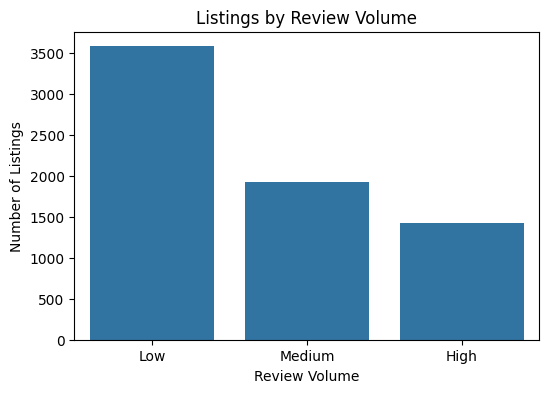

In [22]:
# Add code here 🔧
print(df['number_of_reviews'].describe())

bins = [-1, 10, 50, df['number_of_reviews'].max()]
labels = ['Low', 'Medium', 'High']

df['review_volume'] = pd.cut(df['number_of_reviews'], bins=bins, labels=labels)

print(df['review_volume'].value_counts())
df[['number_of_reviews', 'review_volume']].head(10)

plt.figure(figsize=(6, 4))
sns.countplot(x='review_volume', data=df, order=labels)
plt.title('Listings by Review Volume')
plt.xlabel('Review Volume')
plt.ylabel('Number of Listings')
plt.show()

### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I grouped the column number of reviews into three categories from low, medium, and high.

2. This grouped view is helpful because it makes it easier to understand and take action on. Seeing listings as a high review volume rather then a number with no actual meaning is super helpful for people who aren't technical. The labels also make it easy to compare segments and filter listings.

3. This could be super beneficial for the marketing team because they could use the segments to target campaigns. They could use the categories to promote high listings as customer favorites or look into the low listings and boost them to get more bookings.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [23]:
# Add code here 🔧
df['price_per_guest'] = df['price'] / df['accommodates'].replace(0, np.nan)

df['long_term_stay'] = (df['minimum_nights'] >= 30).astype(int)

print(df['price_per_guest'].describe())
print(df['long_term_stay'].value_counts())

df[['price', 'accommodates', 'price_per_guest', 'minimum_nights', 'long_term_stay']].head(10)

count    6930.000000
mean       38.210087
std        41.292048
min         4.416667
25%        23.760667
50%        32.000000
75%        43.335000
max      1624.000000
Name: price_per_guest, dtype: float64
long_term_stay
0    6898
1      32
Name: count, dtype: int64


,price,accommodates,price_per_guest,minimum_nights,long_term_stay
0,76.00,3,25.333333,2.0,0
1,67.00,2,33.500000,3.0,0
2,190.00,6,31.666667,1.0,0
3,30.00,2,15.000000,1.0,0
4,101.00,2,50.500000,2.0,0
5,55.50,2,27.750000,NaN,0
6,41.00,2,20.500000,2.0,0
7,154.00,4,38.500000,2.0,0
8,50.00,2,25.000000,1.0,0
9,59.13,1,59.130000,14.0,0


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. I created price per guest which is the price divided by the number of guests and long term stay which shows listings that require a stay of 30 nights or more. Price per guest shows me the true value of a listing and long term flag seperates monthly rentals from vacation stays.

2. The main people that will use this are likely hosts, revenue managers, and city partners who will all benefit.

3. These cold help hosts by using the price per guest to see whether their listings are priced competitively against similar sized properties. Revenue mangers could also use the price per guest to compare values across nieghborhoods and spot listings that are over or under priced.



## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [24]:
# Add code here 🔧
print(df['room_type'].value_counts())

room_dummies = pd.get_dummies(df['room_type'], prefix='room', dtype=int)

df = pd.concat([df, room_dummies], axis=1)

print(room_dummies.columns.tolist())
df[['room_type'] + room_dummies.columns.tolist()].head(10)

room_type
Entire home/apt    4732
Private room       2146
Hotel room           38
Shared room          14
Name: count, dtype: int64
['room_Entire home/apt', 'room_Hotel room', 'room_Private room', 'room_Shared room']


,room_type,room_Entire home/apt,room_Hotel room,room_Private room,room_Shared room
0,Entire home/apt,1,0,0,0
1,Private room,0,0,1,0
2,Entire home/apt,1,0,0,0
3,Private room,0,0,1,0
4,Entire home/apt,1,0,0,0
5,Private room,0,0,1,0
6,Private room,0,0,1,0
7,Private room,0,0,1,0
8,Private room,0,0,1,0
9,Private room,0,0,1,0


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. I encoded the room type column because it has a strong effect on price and booking behavior. It was being stored as text and models aren't able to use text categories directly so I converted it to numbers.

2. I used a one hot encoding with pd.get_dummies. I seperated the room types into categoires rather than ranking them.

3. Now using a pricing model you could measure how much each room type changes in price. You could be abel to see how much more an entire home earns than a private room. Using the dashboard and reports columns makes it easy to filter, count, and compare listing via room type.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [25]:
# export csv here 🔧

cols_to_drop = [
    'listing_url', 'scrape_id', 'last_scraped', 'source', 'picture_url',
    'host_url', 'host_thumbnail_url', 'host_picture_url', 'host_about',
    'description', 'neighborhood_overview', 'calendar_last_scraped',
    'calendar_updated', 'license', 'bathrooms_text', 'amenities',
    'host_verifications', 'host_name', 'neighbourhood',
    'host_profile_url', 'price_quote_raw'
]
df = df.drop(columns=cols_to_drop, errors='ignore')  # errors='ignore' skips any column your city doesn't have

for col in ['host_response_rate', 'host_acceptance_rate']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.replace('%', '', regex=False)
        df[col] = pd.to_numeric(df[col], errors='coerce')

for col in ['host_since', 'first_review', 'last_review']:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')

for col in ['host_is_superhost', 'host_has_profile_pic', 'host_identity_verified',
            'has_availability', 'instant_bookable']:
    if col in df.columns:
        df[col] = df[col].map({'t': 1, 'f': 0, True: 1, False: 0})

df['review_volume'] = df['review_volume'].astype('category')

df = df.dropna(subset=['price'])
df = df.drop_duplicates(subset='id')

print(df.shape)
print(df.dtypes)

df.to_csv('cleaned_airbnb_data_7.csv', index=False)
print("File saved: cleaned_airbnb_data_7.csv")

(6930, 76)
id                           int64
name                        object
host_id                      int64
host_profile_id              int64
hosts_time_as_user_years     int64
                             ...  
long_term_stay               int64
room_Entire home/apt         int64
room_Hotel room              int64
room_Private room            int64
room_Shared room             int64
Length: 76, dtype: object
File saved: cleaned_airbnb_data_7.csv


## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. The most interesting part for me was creating new varibles because I hadn't done this before and it helped make the data more useful. The price per guest anfd long term stay were not part of the original data but they make it possible to answer real business questions. They shape the data to fit the decision someone needs to make.

2. I think the long term stay flag would be the most useful for city planners because it shows how many units are used as housing rather than short term rentals for vacation. The hosts could also benefit from price per guest because its a practical way to check whether their units are priced competitively.

3. The next step for me would be to build a dashboard where hosts would be able to filter by nieghborhood, room type, and review volume in order to compare their pricing per guest with similar lisitngs. Following this I'd use the encoded and scaled columns to suggest a compeitive nightly price.

4. Since my learning outcomes focus on EDA, regression modeling, and providing dashboards that make it possible for a non-technical employee to use without having to explain everything this assignment did just that. This assignment went through all three steps which is exactly what I wanted to get out of this course and it helps me bring things back to real world in order to learn things I can translate into work I will be doing after college. This assignment was a building block for future work in the rest of the semester and used a real example that was tangible for me to analyze and learn from.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [30]:
!jupyter nbconvert --to html "assignment_07_data_transformation (1).ipynb"

[NbConvertApp] Converting notebook assignment_07_data_transformation (1).ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 3 image(s).
[NbConvertApp] Writing 431015 bytes to assignment_07_data_transformation (1).html
